# How much is manipulated? Levenshtein distance per condition and block

For every story, the three conditions are built from the same IPA and compared with the **native** IPA:

| condition | t / k | vowels |
|---|---|---|
| **native** | – | – |
| **consistent** | block *b*: every t → `T_ALTS[b]`, every k → `K_ALTS[b]` | block *b*: one vowel (`CONSISTENT_VOWELS[b]`), its words / phonemes quota inside that block |
| **inconsistent** | every t / k → one of the three alternatives, 33 % each (one draw per word) | `word_quota` over the whole story, every vowel with its words / phonemes quota |

**Distance.** Levenshtein distance between the native and the manipulated IPA, on **phoneme units**: a phoneme together with its diacritics (`tʲ`, `tː`, `ẽ`) is one unit, so t → tʲ is one substitution; stress marks are ignored. It is computed word by word (the manipulations never add or remove words) and summed per sentence, block and story.
- `lev`: every substitution / insertion / deletion costs 1
- `lev_feat`: a substitution costs the **number of features that change** (consonants: voicing, place, manner; vowels: height, backness, rounding; plus palatalized / aspirated / long / nasalized). The feature table is in the settings, edit it as you like
- both are also given **per 100 native phonemes**, so blocks of slightly different length can be compared

Nothing is synthesized.

In [1]:
from functions import text_to_ipa_chunks, one_sentence_chunks, VOWELS, BOUNDARY
from word_quota import manipulate_with_quota, normalize_ipa, _word_spans
import re, csv, os, itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from collections import Counter, defaultdict
from IPython.display import display, HTML

c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  warnings.warn(
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## Settings
**Stories.** One entry per story. Mark the block boundaries with a line containing only `###`.
If a story has no `###`, it is cut automatically into `N_BLOCKS` blocks of similar word count at sentence boundaries (useful for a quick test, but use your own blocks for the real thing).

In [4]:
text = ("""
###
Irene Valli lavorava come botanica all'università di Bologna, e da molti anni studiava le piante che crescono vicino al mare. Quell'anno doveva raccogliere alcuni campioni di una piccola pianta con fiori gialli, che cresceva soltanto sulle rocce di un'isola del sud. L'isola si chiamava Calvara, era lunga pochi chilometri e aveva un solo porto, collegato alla costa da un traghetto al giorno. Il traghetto partiva ogni mattina alle sette da Porto Ferrante, una cittadina di pescatori che si trovava alla fine di una lunga linea ferroviaria. Irene aveva preparato il viaggio con attenzione, perché la pianta fioriva soltanto per tre settimane, all'inizio di maggio. Nello zaino aveva messo buste di carta, un quaderno, una piccola pala, una macchina fotografica e una cartina dettagliata dell'isola. Aveva prenotato anche una camera a Porto Ferrante, perché il treno arrivava sempre la sera, dopo la partenza del traghetto.
Il giorno della partenza ha preso il treno a Bologna di primo mattino, e ha cambiato a Roma per continuare verso sud. A Roma ha avuto mezz'ora di tempo, e ha comprato un panino e una bottiglia d'acqua per il resto del viaggio. Il secondo treno era più lento e più vecchio, e si fermava in quasi tutte le stazioni lungo la costa. Nel suo vagone c'erano pochi passeggeri: una coppia di turisti con una grande valigia e un uomo che leggeva il giornale. Dal finestrino si vedevano campi di grano, uliveti e, ogni tanto, una striscia di mare blu dietro le colline. Irene ha passato il viaggio a rileggere i suoi appunti e a controllare sulla cartina i punti dove la pianta era stata trovata. Secondo gli studi precedenti, la pianta cresceva soprattutto sulle rocce della costa nord, esposte al vento e lontane dalle spiagge.
Il treno è arrivato a Porto Ferrante verso le sette di sera, quando il sole era già basso sopra il mare. La stazione era piccola e quasi vuota, con una sola panchina e un orologio fermo da molto tempo sulla stessa ora. Irene ha camminato fino al porto, dove aveva prenotato una camera in una pensione con le finestre sulle barche dei pescatori. Le case erano basse e colorate, e lungo il porto c'erano piccoli negozi che vendevano reti, corde e attrezzi per le barche. La proprietaria della pensione le ha dato la chiave e le ha spiegato dove si comprava il biglietto per il traghetto del mattino. La biglietteria si trovava in una casetta bianca vicino al molo, e apriva mezz'ora prima della partenza della nave. Prima di cena Irene ha fatto una passeggiata sul molo, e da lì ha visto all'orizzonte la sagoma scura dell'isola. Calvara sembrava vicina, ma la proprietaria le aveva detto che il traghetto impiegava quasi due ore per arrivare.
Quella sera il vento ha cominciato a soffiare da nord, prima piano e poi sempre più forte, e le barche nel porto si muovevano molto. Dalla finestra della camera si sentivano soltanto il vento e le corde delle barche che battevano contro gli alberi di legno. Irene è andata a dormire presto, perché voleva essere alla biglietteria alle sei e mezza, prima degli altri passeggeri. Il mattino seguente, quando è arrivata al molo, ha trovato un foglio attaccato alla porta della biglietteria. Sul foglio c'era scritto che il traghetto per Calvara non partiva, a causa del mare agitato e del vento forte. Un impiegato è uscito dalla casetta e ha spiegato ai pochi passeggeri che il traghetto non viaggiava quando le onde superavano i due metri. "Domani il vento dovrebbe calare, ma oggi nessuna nave grande può entrare nel porto dell'isola", ha detto l'impiegato. Gli altri passeggeri, quasi tutti abitanti dell'isola, hanno deciso di aspettare il giorno seguente e sono tornati verso il paese. Irene ha chiesto se esistevano altri modi per arrivare a Calvara nella stessa giornata, anche con un viaggio più lungo. L'impiegato ha pensato per qualche secondo, poi ha detto che sulla costa c'era un altro piccolo porto, più a sud, chiamato Marina di Scoglio. Da lì, a volte, partivano barche private per l'isola, perché il tratto di mare era più corto e più riparato dal vento di nord. Ha aggiunto che un autobus della linea costiera passava davanti al porto alle otto e un quarto, e arrivava a Marina di Scoglio in un'ora. Irene ha ringraziato, ha comprato un biglietto per l'autobus nel bar del porto e si è seduta ad aspettare alla fermata.
###
L'autobus era piccolo e blu, e alle otto e un quarto si è fermato davanti al porto con una precisione che Irene non si aspettava. A bordo c'erano soltanto un'anziana signora con una borsa della spesa e due operai che andavano a lavorare in un cantiere. L'autista ha spiegato che la linea costiera serviva soprattutto gli studenti e i lavoratori dei paesi più piccoli della zona. La strada correva lungo la costa, a volte proprio sopra il mare e a volte tra campi di fichi d'India e muretti di pietra. Da quella strada l'isola si vedeva sempre a sinistra, e cambiava forma lentamente, man mano che l'autobus scendeva verso sud. In alcuni punti il vento era così forte che l'autista rallentava, e le onde bianche si rompevano contro gli scogli sotto la strada. Irene ha notato che più a sud il mare diventava più calmo, perché la costa formava una grande curva che lo proteggeva dal vento. Il viaggio è durato poco più di un'ora, con fermate in tre paesi costruiti sulle colline sopra il mare.
Marina di Scoglio era un porto molto piccolo, con una decina di barche, un bar e una chiesa bianca sopra una scogliera. Nel bar Irene ha chiesto al barista se qualcuno, quel giorno, portava passeggeri a Calvara con la propria barca. Il barista ha detto che in giornate come quella i pescatori restavano a terra, ma che qualcuno lavorava comunque. Poi ha indicato un uomo seduto a un tavolo vicino alla finestra, che beveva un caffè e controllava qualcosa sul telefono. L'uomo si chiamava Nicola Amato, e trasportava merci e persone tra la costa e l'isola con una barca a motore. Nicola ha ascoltato la richiesta di Irene e ha guardato il mare fuori dalla finestra per un lungo momento. Poi ha spiegato che da Marina di Scoglio il viaggio durava solo quaranta minuti, e che il lato sud dell'isola era protetto dalle onde. "Possiamo partire tra un'ora, quando avrò caricato le casse di frutta per il negozio di Calvara", ha detto Nicola. La frutta era destinata all'unico negozio di alimentari dell'isola, che riceveva le merci tre volte alla settimana.
Nicola ha chiesto a Irene di aiutarlo a portare alcune casse sulla barca, e lei ha accettato senza problemi. Mentre caricavano la frutta, Nicola le ha chiesto perché una botanica volesse andare proprio a Calvara in quella stagione. Irene gli ha raccontato della pianta con i fiori gialli, e gli ha mostrato una fotografia sul suo quaderno. Nicola ha detto di aver visto quei fiori molte volte, soprattutto vicino a una vecchia torre di guardia sulla costa nord. La barca era lunga circa otto metri, con una piccola cabina, due panche di legno e un motore che faceva molto rumore. Nicola ha dato a Irene un giubbotto di salvataggio arancione e le ha mostrato dove sedersi per bagnarsi il meno possibile. Irene ha messo il quaderno dentro una busta di plastica, perché sapeva che durante il viaggio gli spruzzi d'acqua arrivavano dappertutto.
Appena usciti dal porto, la barca ha cominciato a salire e scendere sulle onde lunghe, ma con un ritmo regolare. Nicola teneva il timone con una mano e con l'altra indicava a Irene i punti della costa che conosceva da quando era bambino. A metà strada hanno incontrato un gruppo di delfini, che hanno nuotato accanto alla barca per qualche minuto e poi si sono allontanati. Dopo mezz'ora di viaggio la sagoma dell'isola è diventata più chiara, e Irene ha potuto distinguere le rocce, i campi e le prime case. Più si avvicinavano all'isola, più il mare diventava calmo, perché le colline di Calvara bloccavano il vento di nord. Il porto dell'isola era piccolo, con le case colorate disposte intorno a una piazza e una strada che saliva verso l'interno. Sul molo alcuni uomini aspettavano le casse di frutta, e hanno aiutato Nicola a scaricarle con movimenti rapidi e precisi. Nicola ha spiegato che la torre di guardia si trovava a circa un'ora di cammino dal porto, lungo un sentiero ben segnato. Ha detto anche che sarebbe ripartito per la costa alle cinque, ma che il traghetto grande sarebbe tornato in servizio la mattina dopo. Irene ha deciso di restare sull'isola per la notte, così avrebbe avuto tutto il tempo necessario per il suo lavoro. Ha prenotato una camera nell'unico albergo del paese, ha lasciato lo zaino più pesante alla reception e ha preso solo gli strumenti.
###
Il sentiero partiva dietro la chiesa del paese e saliva tra campi abbandonati, muretti di pietra e piccoli boschi di pini. Lungo la strada ha incontrato soltanto un contadino con un asino carico di legna, che l'ha salutata con un cenno della mano. Dopo mezz'ora di salita Irene è arrivata sulla cima della collina, da cui si vedevano tutta l'isola e, in lontananza, la costa. Il cielo era sereno, ma il vento portava fino in cima l'odore del sale e il rumore delle onde. Da lì il sentiero scendeva verso nord, dove il vento soffiava ancora forte e il mare era bianco di schiuma. Ogni tanto Irene si fermava per bere un po' d'acqua e per controllare sulla cartina la sua posizione rispetto alla torre. La torre di guardia era una costruzione rotonda di pietra grigia, senza tetto, costruita molti secoli prima per controllare le navi. Intorno alla torre le rocce erano coperte di piccole piante basse, che crescevano nelle fessure dove si raccoglieva un po' di terra.
Irene ha cercato a lungo tra le rocce, camminando con attenzione perché il terreno era irregolare e in alcuni punti scivoloso. Dopo circa venti minuti ha trovato il primo gruppo di fiori gialli, in una fessura riparata dal vento sotto il muro della torre. Ha fotografato le piante da vicino, ha misurato la loro altezza e ha scritto sul quaderno la posizione esatta di ogni gruppo. Poi ha raccolto con la piccola pala alcune piante intere, con le radici e un po' di terra, e le ha messe nelle buste. Su ogni busta ha scritto la data e un numero, che corrispondeva a una riga del suo quaderno. Il suo lavoro richiedeva campioni di zone diverse, perché voleva capire se le piante cambiavano a seconda della distanza dal mare. Per questo motivo ha continuato a cercare lungo la costa, prima verso est e poi verso ovest, seguendo un vecchio sentiero di pescatori. In alcuni punti doveva abbassarsi o sedersi sulle rocce, perché le piante crescevano in fessure molto strette e profonde. Nel pomeriggio aveva trovato sette gruppi di piante, alcuni molto vicini all'acqua e altri più in alto, quasi in cima alla scogliera. Ha notato che le piante più vicine al mare erano più basse e avevano foglie più spesse, forse per proteggersi dal sale. Era un'osservazione interessante, che avrebbe controllato con calma in laboratorio, con gli strumenti di misura dell'università.
Verso le sei il vento ha cominciato a calare, e il mare a nord dell'isola è diventato di nuovo blu. Irene è tornata al paese seguendo lo stesso sentiero, con lo zaino pieno di buste e il quaderno pieno di appunti. In albergo ha sistemato i campioni in una scatola di cartone, che ha lasciato aperta per far circolare l'aria durante la notte. A cena, nella piccola trattoria della piazza, ha incontrato Nicola, che alla fine non era ripartito per la costa. La trattoria offriva soltanto due piatti al giorno, e quella sera c'erano pasta con le alici e pesce al forno. Nicola le ha spiegato che aveva deciso di aspettare il mattino, perché doveva caricare alcune casse vuote da riportare a Marina di Scoglio. Poi le ha chiesto se avesse trovato i fiori, e Irene gli ha raccontato della torre e delle piante vicino al mare. "Allora è stato un viaggio utile, anche se ha dovuto fare il giro più lungo", ha detto Nicola.
La mattina seguente il mare era calmo e il cielo era limpido, e il traghetto grande è arrivato in porto puntuale. Prima di salire a bordo Irene ha salutato Nicola, che stava già caricando le casse vuote sulla sua barca. Sul traghetto ha cercato un posto all'ombra, e ha tenuto la scatola dei campioni sulle ginocchia. Durante la traversata ha guardato l'isola allontanarsi, e ha riconosciuto da lontano la torre di guardia sulla costa nord. A Porto Ferrante ha ripreso il treno verso Roma, e poi quello per Bologna, dove è arrivata a tarda sera. Il giorno dopo ha portato i campioni in laboratorio, ha pulito le radici e ha preparato le piante per le analisi. Nelle settimane successive ha confrontato le misure delle piante vicine al mare con quelle delle piante più lontane. I risultati confermavano la sua osservazione: le foglie diventavano più spesse quando la pianta cresceva più vicino all'acqua salata. Irene ha scritto un breve articolo su questo risultato, e nella descrizione del metodo ha spiegato anche il percorso seguito per arrivare sull'isola.
""")
STORIES = {
    "story1": text,      # replace with your three stories, e.g. "story1": open("story1.txt").read()
    # "story2": ...,
    # "story3": ...,
}
BLOCK_SEP = "###"
N_BLOCKS  = 3
NORMALIZE = {"ɪ": "i"}

# ---- consonants ----
T_ALTS = ["tʲ", "θ", "ɖ"]           # consistent: block 1, 2, 3   | inconsistent: 33 % each
K_ALTS = ["x", "ɡ", "kʲ"]
INCONSISTENT_SAME_IN_WORD = True     # inconsistent: every t (k) of one word gets the same alternative

# ---- vowels: replacement + quota (the quota is for the WHOLE story) ----
VOWEL_TARGETS = {"e": dict(new="ø", words=290, phonemes=320),
                 "i": dict(new="y", words=246, phonemes=288),
                 "o": dict(new="ə", words=236, phonemes=258)}

            #   "targets": [{"old": "e", "new": "ø", "words": 290, "phonemes": 320},     # <- your v1
            #               {"old": "o", "new": "ə", "words": 246, "phonemes": 288},     # <- your v2
            #               {"old": "i", "new": "y", "words": 236, "phonemes": 258}
CONSISTENT_VOWELS = ["e", "i", "o"]  # consistent: block 1 manipulates e, block 2 i, block 3 o
OCCURRENCES = "all"                  # "all" (≈ phonemes, words consistent) or "partial" (exact phonemes)

SEED    = 1                          # the seed used for the main tables
N_SEEDS = 20                         # seeds for the variability check

### Feature table (for `lev_feat`)
Each base phoneme gets one value per feature; the cost of a substitution is the number of features with different values, plus one per diacritic feature (ʲ ʰ ː ̃) that differs. A consonant ↔ vowel substitution costs 3 + diacritics. Unknown symbols cost 1. Edit freely.

In [5]:
CONS = {   # voice, place, manner
 'p':('-','bilabial','stop'), 'b':('+','bilabial','stop'), 'm':('+','bilabial','nasal'),
 'ɸ':('-','bilabial','fricative'), 'β':('+','bilabial','fricative'),
 'f':('-','labiodental','fricative'), 'v':('+','labiodental','fricative'), 'ʋ':('+','labiodental','approximant'),
 'θ':('-','dental','fricative'), 'ð':('+','dental','fricative'),
 't':('-','alveolar','stop'), 'd':('+','alveolar','stop'), 'n':('+','alveolar','nasal'),
 's':('-','alveolar','fricative'), 'z':('+','alveolar','fricative'), 'S':('-','alveolar','fricative'),
 'ʦ':('-','alveolar','affricate'), 'ʣ':('+','alveolar','affricate'),
 'r':('+','alveolar','trill'), 'ɾ':('+','alveolar','tap'), 'ɹ':('+','alveolar','approximant'), 'l':('+','alveolar','lateral'),
 'ʃ':('-','postalveolar','fricative'), 'ʒ':('+','postalveolar','fricative'),
 'ʧ':('-','postalveolar','affricate'), 'ʤ':('+','postalveolar','affricate'),
 'ɕ':('-','alveolopalatal','fricative'), 'ʨ':('-','alveolopalatal','affricate'), 'ʥ':('+','alveolopalatal','affricate'),
 'ʈ':('-','retroflex','stop'), 'ɖ':('+','retroflex','stop'), 'ɳ':('+','retroflex','nasal'),
 'ʂ':('-','retroflex','fricative'), 'ɽ':('+','retroflex','tap'), 'ɻ':('+','retroflex','approximant'),
 'c':('-','palatal','stop'), 'ɟ':('+','palatal','stop'), 'ɲ':('+','palatal','nasal'), 'ç':('-','palatal','fricative'),
 'ʝ':('+','palatal','fricative'), 'j':('+','palatal','approximant'), 'ʎ':('+','palatal','lateral'),
 'k':('-','velar','stop'), 'ɡ':('+','velar','stop'), 'g':('+','velar','stop'), 'ŋ':('+','velar','nasal'),
 'x':('-','velar','fricative'), 'ɣ':('+','velar','fricative'), 'ɰ':('+','velar','approximant'),
 'w':('+','labiovelar','approximant'),
 'q':('-','uvular','stop'), 'ɴ':('+','uvular','nasal'), 'χ':('-','uvular','fricative'), 'ʁ':('+','uvular','fricative'),
 'h':('-','glottal','fricative'), 'ʔ':('-','glottal','stop'),
}
VOWS = {   # height, backness, rounding
 'i':('close','front','-'), 'y':('close','front','+'), 'ɨ':('close','central','-'), 'ɯ':('close','back','-'),
 'u':('close','back','+'), 'ɪ':('near-close','front','-'), 'ʊ':('near-close','back','+'),
 'e':('close-mid','front','-'), 'ø':('close-mid','front','+'), 'ɤ':('close-mid','back','-'), 'o':('close-mid','back','+'),
 'ə':('mid','central','-'),
 'ɛ':('open-mid','front','-'), 'œ':('open-mid','front','+'), 'ɜ':('open-mid','central','-'),
 'ʌ':('open-mid','back','-'), 'ɔ':('open-mid','back','+'),
 'æ':('near-open','front','-'), 'ɐ':('near-open','central','-'),
 'a':('open','front','-'), 'ɑ':('open','back','-'), 'ɒ':('open','back','+'),
}
DIACRITICS = {'ʲ': 'palatalized', 'ʰ': 'aspirated', 'ː': 'long', '̃': 'nasalized'}
INDEL_FEAT = 3          # cost of inserting / deleting a whole unit in lev_feat

## Phoneme units and Levenshtein distance

In [6]:
STRESS = {"ˈ", "ˌ"}

def units(word):
    '''A word -> list of (base, frozenset(diacritic features)); stress marks dropped.'''
    out = []
    for c in word:
        if c in STRESS:
            continue
        if c in DIACRITICS and out:
            b, d = out[-1]; out[-1] = (b, d | {DIACRITICS[c]})
        elif c in DIACRITICS or c in BOUNDARY:
            continue
        else:
            out.append((c, frozenset({"long"}) if c == "S" else frozenset()))
    return out

_unknown = set()
def feat_cost(a, b):
    '''Number of features that differ between two units.'''
    if a == b:
        return 0
    (ba, da), (bb, db) = a, b
    dia = len(da ^ db)
    fa = CONS.get(ba) or VOWS.get(ba); fb = CONS.get(bb) or VOWS.get(bb)
    if fa is None or fb is None:
        _unknown.update(x for x, f in ((ba, fa), (bb, fb)) if f is None)
        return (ba != bb) + dia
    if (ba in CONS) != (bb in CONS):
        return 3 + dia
    return sum(x != y for x, y in zip(fa, fb)) + dia

def lev(a, b, cost=None, indel=1):
    '''Levenshtein distance between two unit lists + the list of edit operations (native, manipulated).'''
    cost = cost or (lambda x, y: 0 if x == y else 1)
    n, m = len(a), len(b)
    D = np.zeros((n + 1, m + 1)); D[:, 0] = np.arange(n + 1) * indel; D[0, :] = np.arange(m + 1) * indel
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i-1, j] + indel, D[i, j-1] + indel, D[i-1, j-1] + cost(a[i-1], b[j-1]))
    ops, i, j = [], n, m                                     # backtrace
    while i or j:
        if i and j and D[i, j] == D[i-1, j-1] + cost(a[i-1], b[j-1]):
            if a[i-1] != b[j-1]: ops.append((a[i-1], b[j-1]))
            i, j = i - 1, j - 1
        elif i and D[i, j] == D[i-1, j] + indel:
            ops.append((a[i-1], None)); i -= 1
        else:
            ops.append((None, b[j-1])); j -= 1
    return D[n, m], ops[::-1]

def show(u):
    if u is None: return "∅"
    b, d = u
    return b + "".join(k for k, v in DIACRITICS.items() if v in d)

# quick check
assert lev(units("ˈtetto"), units("ˈtʲetʲto"))[0] == 2
assert lev(units("kasa"), units("xasa"), feat_cost)[0] == 1        # k -> x: manner only
assert feat_cost(units("t")[0], units("θ")[0]) == 2                  # place + manner
print("ok")

ok


## Building the three conditions
`build_story(name, text, seed)` → for every condition a list of blocks, each block a list of (native IPA, manipulated IPA) sentences.

In [7]:
_auto_warned = set()

def split_blocks(text):
    '''Blocks from ### lines, or N_BLOCKS blocks of similar word count at sentence boundaries.'''
    parts = [p.strip() for p in re.split(rf"^\s*{re.escape(BLOCK_SEP)}\s*$", text, flags=re.M) if p.strip()]
    if len(parts) > 1:
        return parts
    sents = one_sentence_chunks(text)
    nw = np.cumsum([len(s.split()) for s in sents])
    cuts = [int(np.argmin(np.abs(nw - nw[-1] * b / N_BLOCKS))) + 1 for b in range(1, N_BLOCKS)]
    bounds = [0] + cuts + [len(sents)]
    if text not in _auto_warned:
        print(f"   (no '{BLOCK_SEP}' found: cut automatically into {N_BLOCKS} blocks)"); _auto_warned.add(text)
    return [" ".join(sents[a:b]) for a, b in zip(bounds, bounds[1:])]

def vowel_rule(vowels):
    return {"kind": "word_quota", "occurrences": OCCURRENCES, "batch": 10, "order": "rotate",
            "targets": [{"old": v, "new": VOWEL_TARGETS[v]["new"], "words": VOWEL_TARGETS[v]["words"],
                         "phonemes": VOWEL_TARGETS[v].get("phonemes")} for v in vowels]}

def build_story(text, seed, verbose=False):
    blocks = split_blocks(text)
    nat = [normalize_ipa(text_to_ipa_chunks(b), NORMALIZE, verbose=False) for b in blocks]
    out = {"native": [list(zip(c, c)) for c in nat]}
    # consistent: own t / k alternative and one vowel per block
    cons = []
    for b, chunks in enumerate(nat):
        rules = [{"kind": "substitute", "map": {"t": T_ALTS[b % len(T_ALTS)], "k": K_ALTS[b % len(K_ALTS)]}},
                 vowel_rule([CONSISTENT_VOWELS[b % len(CONSISTENT_VOWELS)]])]
        if verbose: print(f"consistent, block {b + 1}:")
        m = manipulate_with_quota(chunks, rules, seed=seed * 100 + b, verbose=verbose)
        cons.append(list(zip(chunks, m)))
    out["consistent"] = cons
    # inconsistent: t / k 33 % each, vowel quotas over the whole story
    flat = [c for chunks in nat for c in chunks]
    rules = [{"kind": "substitute_prob", "same_in_word": INCONSISTENT_SAME_IN_WORD,
              "map": {"t": {a: 1 for a in T_ALTS}, "k": {a: 1 for a in K_ALTS}}},
             vowel_rule(list(VOWEL_TARGETS))]
    if verbose: print("inconsistent, whole story:")
    m = manipulate_with_quota(flat, rules, seed=seed, verbose=verbose)
    inc, k = [], 0
    for chunks in nat:
        inc.append(list(zip(chunks, m[k:k + len(chunks)]))); k += len(chunks)
    out["inconsistent"] = inc
    return out

## Measuring

In [8]:
CONDS = ["native", "consistent", "inconsistent"]

def category(op):
    a, b = op
    base = (a or b)[0]
    if base == "t": return "t"
    if base == "k": return "k"
    if base in VOWEL_TARGETS: return base
    return "other"

def measure(story):
    '''-> rows (one per condition × block) and the list of all edit operations.'''
    rows, all_ops = [], []
    for cond in CONDS:
        for b, sents in enumerate(story[cond]):
            r = dict(condition=cond, block=b + 1, words=0, phonemes=0, lev=0.0, lev_feat=0.0, words_changed=0)
            cats = Counter()
            for nat_s, man_s in sents:
                wn = [nat_s[a:c] for a, c in _word_spans(nat_s)]
                wm = [man_s[a:c] for a, c in _word_spans(man_s)]
                pairs = list(zip(wn, wm)) if len(wn) == len(wm) else [(" ".join(wn), " ".join(wm))]
                for x, y in pairs:
                    ux, uy = units(x), units(y)
                    d, ops = lev(ux, uy)
                    df, _ = lev(ux, uy, feat_cost, INDEL_FEAT)
                    r["lev"] += d; r["lev_feat"] += df; r["words_changed"] += d > 0
                    for op in ops:
                        cats[category(op)] += 1
                        all_ops.append((cond, b + 1, show(op[0]), show(op[1]), feat_cost(*op) if None not in op else INDEL_FEAT))
                r["words"] += len(wn); r["phonemes"] += sum(len(units(x)) for x in wn)
            r["lev_100"] = 100 * r["lev"] / r["phonemes"]
            r["lev_feat_100"] = 100 * r["lev_feat"] / r["phonemes"]
            r.update({f"n_{c}": cats[c] for c in ["t", "k", *VOWEL_TARGETS, "other"]})
            rows.append(r)
    for cond in CONDS:                                        # whole story
        rs = [r for r in rows if r["condition"] == cond]
        tot = {k: sum(r[k] for r in rs) for k in rs[0] if k not in ("condition", "block", "lev_100", "lev_feat_100")}
        tot.update(condition=cond, block="all", lev_100=100 * tot["lev"] / tot["phonemes"],
                   lev_feat_100=100 * tot["lev_feat"] / tot["phonemes"])
        rows.append(tot)
    return rows, all_ops

results, ops_all = {}, {}
for name, txt in STORIES.items():
    print(f"── {name}")
    story = build_story(txt, SEED, verbose=True)
    results[name], ops_all[name] = measure(story)
if _unknown:
    print("⚠ symbols not in the feature table (cost 1):", sorted(_unknown))

── story1
consistent, block 1:
word_quota: 290 candidate words, 0 of them can take more than one target
   e → ø: 290 candidate words (320 phonemes) -> 290 of 290 words, 320 phonemes (target 320)
consistent, block 2:
word_quota: 223 candidate words, 0 of them can take more than one target
   i → y: 223 candidate words (246 phonemes) -> 223 of 246 words, 246 phonemes (target 288, closest reachable)   ⚠ 23 short: no assignment with one change per word can reach the quota
consistent, block 3:
word_quota: 248 candidate words, 0 of them can take more than one target
   o → ə: 248 candidate words (304 phonemes) -> 236 of 236 words, 275 phonemes (target 258, closest reachable)
inconsistent, whole story:
word_quota: 1686 candidate words, 467 of them can take more than one target
   e → ø: 819 candidate words (912 phonemes) -> 290 of 290 words, 320 phonemes (target 320)
   i → y: 676 candidate words (740 phonemes) -> 246 of 246 words, 288 phonemes (target 288)
   o → ə: 728 candidate words (862

## Results table

In [9]:
COLS = ["condition", "block", "words", "phonemes", "words_changed", "lev", "lev_100", "lev_feat", "lev_feat_100",
        "n_t", "n_k", *[f"n_{v}" for v in VOWEL_TARGETS], "n_other"]

def table_html(rows):
    fmt = lambda v: f"{v:.1f}" if isinstance(v, float) else str(v)
    head = "".join(f"<th style='padding:3px 8px;text-align:right'>{c}</th>" for c in COLS)
    body = ""
    for r in rows:
        style = "font-weight:600;border-top:1px solid #ccc" if r["block"] == "all" else ""
        body += f"<tr style='{style}'>" + "".join(f"<td style='padding:2px 8px;text-align:right'>{fmt(r[c])}</td>" for c in COLS) + "</tr>"
    return f"<table style='border-collapse:collapse;font-size:12px;font-family:system-ui'><tr>{head}</tr>{body}</table>"

for name, rows in results.items():
    order = sorted(rows, key=lambda r: (CONDS.index(r["condition"]), str(r["block"])))
    display(HTML(f"<h4 style='margin:14px 0 4px'>{name}</h4>" + table_html(order)))
print("lev_100 / lev_feat_100 = distance per 100 native phonemes;  n_* = number of edits per native phoneme")

condition,block,words,phonemes,words_changed,lev,lev_100,lev_feat,lev_feat_100,n_t,n_k,n_e,n_i,n_o,n_other
native,1,733,3275,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,2,735,3259,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,3,740,3309,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
native,all,2208,9843,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
consistent,1,733,3275,447,652.0,19.9,652.0,19.9,216,116,320,0,0,0
consistent,2,735,3259,437,611.0,18.7,813.0,24.9,202,163,0,246,0,0
consistent,3,740,3309,361,617.0,18.6,1382.0,41.8,215,127,0,0,275,0
consistent,all,2208,9843,1245,1880.0,19.1,2847.0,28.9,633,406,320,246,275,0
inconsistent,1,733,3275,404,617.0,18.8,918.0,28.0,216,116,111,94,80,0
inconsistent,2,735,3259,421,637.0,19.5,958.0,29.4,202,163,90,92,90,0


lev_100 / lev_feat_100 = distance per 100 native phonemes;  n_* = number of edits per native phoneme


## Distance per block and condition

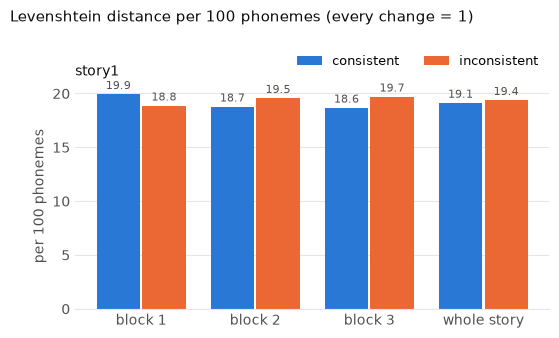

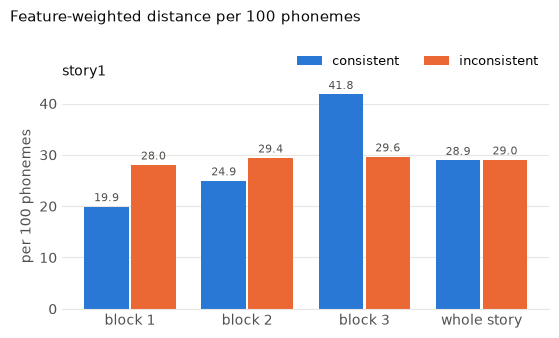

native is 0 everywhere (sanity check): True


In [10]:
C_COL = {"native": "#9ca3af", "consistent": "#2a78d6", "inconsistent": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e7e6e2"

def style(ax):
    ax.spines[["top", "right", "left"]].set_visible(False); ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0); ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)

for metric, title in (("lev_100", "Levenshtein distance per 100 phonemes (every change = 1)"),
                      ("lev_feat_100", "Feature-weighted distance per 100 phonemes")):
    names = list(results)
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names) + 1, 3.4), squeeze=False, sharey=True)
    for ax, name in zip(axes[0], names):
        rows = results[name]
        groups = sorted({r["block"] for r in rows if r["block"] != "all"}) + ["all"]
        x = np.arange(len(groups)); w = 0.38
        for k, cond in enumerate(["consistent", "inconsistent"]):
            v = [next(r[metric] for r in rows if r["condition"] == cond and r["block"] == g) for g in groups]
            bars = ax.bar(x + (k - 0.5) * (w + 0.02), v, w, color=C_COL[cond], label=cond)
            ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color=MUTED)
        ax.set_xticks(x, [f"block {g}" if g != "all" else "whole story" for g in groups], color=INK)
        ax.set_title(name, loc="left", fontsize=10, color=INK); style(ax)
    axes[0][0].set_ylabel("per 100 phonemes", color=MUTED)
    axes[0][-1].legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1.02), ncol=2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, color=INK)
    plt.tight_layout(); plt.show()
print("native is 0 everywhere (sanity check):",
      all(r["lev"] == 0 for rows in results.values() for r in rows if r["condition"] == "native"))

## What the distance is made of
Edits per block, split by the native phoneme that was changed.

In [ ]:
CATS = ["t", "k", *VOWEL_TARGETS, "other"]
CAT_COL = dict(zip(CATS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#9ca3af"]))
names = list(results)
fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names) + 1, 3.4), squeeze=False, sharey=True)
for ax, name in zip(axes[0], names):
    rows = [r for r in results[name] if r["block"] != "all" and r["condition"] != "native"]
    labels = [f"{'cons' if r['condition'] == 'consistent' else 'incons'}\nblock {r['block']}" for r in rows]
    bottom = np.zeros(len(rows))
    for c in CATS:
        v = np.array([r[f"n_{c}"] for r in rows])
        if v.sum() == 0: continue
        ax.bar(range(len(rows)), v, 0.65, bottom=bottom, color=CAT_COL[c], edgecolor="white", linewidth=2, label=c)
        bottom += v
    ax.set_xticks(range(len(rows)), labels, fontsize=8, color=INK)
    ax.set_title(name, loc="left", fontsize=10, color=INK); style(ax)
axes[0][0].set_ylabel("edits", color=MUTED)
axes[0][-1].legend(frameon=False, fontsize=9, ncol=len(CATS), loc="lower right", bbox_to_anchor=(1, 1.02))
plt.tight_layout(); plt.show()

## Which substitutions, and what they cost in features
Every native → manipulated pair that occurred, with its count and its feature cost. Check this table when you edit the feature table.

In [ ]:
for name, ops in ops_all.items():
    cnt = Counter((cond, a, b, c) for cond, blk, a, b, c in ops)
    print(f"── {name}")
    for cond in ["consistent", "inconsistent"]:
        items = sorted(((a, b, c, n) for (cd, a, b, c), n in cnt.items() if cd == cond), key=lambda x: (x[0], -x[3]))
        print(f"  {cond}: " + ",  ".join(f"{a}→{b} ×{n} (cost {c})" for a, b, c, n in items))

## Variability over seeds
The vowel words are drawn at random (both conditions) and so are the t / k alternatives (inconsistent). Mean ± SD over `N_SEEDS` seeds, per 100 phonemes.
With unit cost, the distance is fixed by construction (every t and k changes, and the vowel quotas are exact); with feature weights the inconsistent condition varies with the alternatives drawn.

In [ ]:
for name, txt in STORIES.items():
    acc = defaultdict(list)
    for sd in range(N_SEEDS):
        rows, _ = measure(build_story(txt, sd))
        for r in rows:
            if r["condition"] != "native":
                acc[(r["condition"], r["block"])].append((r["lev_100"], r["lev_feat_100"]))
    print(f"── {name}   ({N_SEEDS} seeds)")
    print(f"   {'condition':<13}{'block':>6}{'lev/100':>16}{'feat/100':>16}")
    for (cond, blk), v in sorted(acc.items(), key=lambda kv: (kv[0][0], str(kv[0][1]))):
        v = np.array(v)
        print(f"   {cond:<13}{str(blk):>6}{v[:, 0].mean():>10.2f} ± {v[:, 0].std():<4.2f}{v[:, 1].mean():>10.2f} ± {v[:, 1].std():.2f}")

## Distance between the two accented conditions
Not against native, but consistent vs inconsistent directly, per block (every change = 1, per 100 phonemes).

In [ ]:
for name, txt in STORIES.items():
    st = build_story(txt, SEED)
    out = []
    for b, (sc, si) in enumerate(zip(st["consistent"], st["inconsistent"])):
        d = n = 0
        for (nat_s, c_s), (_, i_s) in zip(sc, si):
            for (a1, b1), (a2, b2) in zip(_word_spans(c_s), _word_spans(i_s)):
                d += lev(units(c_s[a1:b1]), units(i_s[a2:b2]))[0]
            n += sum(len(units(nat_s[a:c])) for a, c in _word_spans(nat_s))
        out.append(f"block {b + 1}: {100 * d / n:.1f}")
    print(f"{name}: consistent vs inconsistent  " + "   ".join(out))

## Save

In [ ]:
os.makedirs("output_online", exist_ok=True)
with open("output_online/levenshtein_conditions.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.DictWriter(f, fieldnames=["story"] + COLS)
    wr.writeheader()
    for name, rows in results.items():
        for r in rows:
            wr.writerow({"story": name, **{c: (round(r[c], 3) if isinstance(r[c], float) else r[c]) for c in COLS}})
with open("output_online/levenshtein_edits.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f); wr.writerow(["story", "condition", "block", "native", "manipulated", "feature_cost"])
    for name, ops in ops_all.items():
        for op in ops:
            wr.writerow([name, *op])
print("written: output_online/levenshtein_conditions.csv, output_online/levenshtein_edits.csv")